# Thực nghiệm CNN Policy Network & Mixed MCTS (Cấp 5) trên Caro 11×11

Notebook thực hiện khép kín:
1. Khởi tạo môi trường `CaroEnv` (11×11, thắng 5 quân liên tiếp) và nạp tác tử `CNNAgent` từ `src/agents/cnn_agent.py`.
2. Sinh dữ liệu tự chơi (`Expert` vs `Non-Expert`), tăng cường 8 phép đối xứng $D_4$ và huấn luyện 2 kiến trúc **Fast Policy Network** (2 lớp ẩn Dense) & **Strong Policy Network** (3 lớp ẩn Dense) theo **Chương 10 sách *AlphaGo Simplified***.
3. Kiểm chứng các tình huống chiến thuật bắt buộc (Thắng ngay 5 quân, Chặn thắng 5 quân, Tạo/Chặn chuỗi 4 mở hai đầu).
4. **Chạy trực tiếp các cặp ván đấu đối kháng có cân bằng lượt đi trước/sau (X/O) ngay trong Notebook bằng hàm `play_game()` và `run_matchup()` **.
5. Tổng hợp bảng `results_df`, `summary_df` (Thắng/Hòa/Thua, Score), `performance_df` (số nước đi trung bình, thời gian suy nghĩ `ms`, số lượt tìm kiếm `search_count`), phân tích Ablation Study và vẽ biểu đồ trực quan.

## 1. Import cấu hình và định nghĩa hàm chạy ván đấu trực tiếp (`play_game`, `run_matchup`)

In [1]:
import sys
from pathlib import Path
import time
import random
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Tự động xác định thư mục gốc dự án caro_ai_11x11
PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
for parent in [PROJECT_ROOT, *PROJECT_ROOT.parents]:
    if (parent / "src" / "caro_env.py").exists():
        PROJECT_ROOT = parent
        break

SRC_DIR = PROJECT_ROOT / "src"
for p in (str(PROJECT_ROOT), str(SRC_DIR)):
    if p not in sys.path:
        sys.path.insert(0, p)

from caro_env import CaroEnv
from heuristic import get_candidate_actions, evaluate_cell_threat, evaluate_board
from agents.base_agent import BaseAgent
from agents.cnn_agent import (
    CNNAgent,
    HAS_TENSORFLOW,
    encode_board,
    augment_state_action,
    expert_select_action,
    non_expert_select_action,
    generate_expert_dataset,
)

BOARD_SIZE = 11
WIN_LENGTH = 5
GAMES_PER_MATCHUP = 40  # Đổi bên X/O luân phiên: 20 ván A cầm X (đi trước), 20 ván A cầm O (đi sau)
SEED = 42

RESULTS_DIR = PROJECT_ROOT / "results"
TABLE_DIR = RESULTS_DIR / "tables"
CHART_DIR = RESULTS_DIR / "figures"
CHECKPOINTS_DIR = PROJECT_ROOT / "checkpoints"
for folder in (TABLE_DIR, CHART_DIR, CHECKPOINTS_DIR):
    folder.mkdir(parents=True, exist_ok=True)

plt.rcParams["figure.dpi"] = 120
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3


class RandomBaselineAgent(BaseAgent):
    """Tác tử chọn nước đi ngẫu nhiên đồng đều trên bàn cờ (dùng để so sánh cơ sở trong Notebook)."""
    def __init__(self, seed: int = 42, name: str = "Random"):
        super().__init__(name=name)
        self.rng = random.Random(seed)
        self.last_move_time_ms = 0.0
        self.last_search_count = 1

    def select_action(self, env: CaroEnv) -> int:
        t0 = time.perf_counter()
        legal = env.legal_actions()
        action = int(self.rng.choice(legal))
        self.last_move_time_ms = (time.perf_counter() - t0) * 1000.0
        self.last_search_count = 1
        return action


class NonExpertBaselineAgent(BaseAgent):
    """Tác tử Bán chuyên (50% đi nước Expert, 50% đi ngẫu nhiên vùng lân cận theo Mục 10.1.1 sách AlphaGo Simplified)."""
    def __init__(self, random_prob: float = 0.5, seed: int = 42, name: str = "Non-Expert (50%)"):
        super().__init__(name=name)
        self.random_prob = random_prob
        self.rng = np.random.default_rng(seed)
        self.last_move_time_ms = 0.0
        self.last_search_count = 1

    def select_action(self, env: CaroEnv) -> int:
        t0 = time.perf_counter()
        cands = get_candidate_actions(env, radius=2)
        action = int(non_expert_select_action(env, random_prob=self.random_prob, rng=self.rng))
        self.last_move_time_ms = (time.perf_counter() - t0) * 1000.0
        self.last_search_count = max(1, len(cands))
        return action


def play_game(agent_x: BaseAgent, agent_o: BaseAgent, board_size: int = 11, win_length: int = 5, record: bool = False) -> dict:
    """Chạy trực tiếp 1 ván đấu trong Notebook; hoàn toàn KHÔNG phụ thuộc src/tournament.py."""
    env = CaroEnv(board_size=board_size, win_length=win_length)
    history = [env.board.copy()] if record else []
    x_times, o_times = [], []
    x_search, o_search = [], []

    while not env.is_terminal():
        agent = agent_x if env.current_player == 1 else agent_o
        t0 = time.perf_counter()
        action = agent.select_action(env)
        fallback_ms = (time.perf_counter() - t0) * 1000.0
        env.step(action)

        elapsed = float(getattr(agent, "last_move_time_ms", fallback_ms))
        searched = int(getattr(agent, "last_search_count", 1))
        if agent is agent_x:
            x_times.append(elapsed)
            x_search.append(searched)
        else:
            o_times.append(elapsed)
            o_search.append(searched)

        if record:
            history.append(env.board.copy())

    return {
        "winner": env.winner if env.winner != 0 else None,
        "moves": len(env.history),
        "x_avg_ms": float(np.mean(x_times)) if x_times else 0.0,
        "o_avg_ms": float(np.mean(o_times)) if o_times else 0.0,
        "x_avg_search_count": float(np.mean(x_search)) if x_search else 0.0,
        "o_avg_search_count": float(np.mean(o_search)) if o_search else 0.0,
        "history": history,
        "move_sequence": env.history.copy(),
    }


def run_matchup(factory_a, factory_b, games: int = 40, board_size: int = 11, win_length: int = 5, seed: int = 42) -> list[dict]:
    """
    Chạy chuỗi ván đấu đối kháng giữa A và B ngay trong Notebook (không gọi src/tournament.py).
    A và B đổi bên X/O luân phiên:
      - Ván chẵn (0, 2, 4...): A cầm X (đi trước), B cầm O (đi sau).
      - Ván lẻ (1, 3, 5...): B cầm X (đi trước), A cầm O (đi sau).
    """
    rows = []
    for game_index in range(games):
        a_agent = factory_a(seed + 2 * game_index)
        b_agent = factory_b(seed + 2 * game_index + 1)

        a_is_x = (game_index % 2 == 0)
        agent_x, agent_o = (a_agent, b_agent) if a_is_x else (b_agent, a_agent)

        result = play_game(agent_x, agent_o, board_size=board_size, win_length=win_length, record=False)
        winner = result["winner"]
        if winner is None:
            outcome = "Draw"
        elif (winner == 1 and a_is_x) or (winner == -1 and not a_is_x):
            outcome = "A"
        else:
            outcome = "B"

        rows.append({
            "game": game_index + 1,
            "winner": outcome,
            "moves": result["moves"],
            "a_side": "X" if a_is_x else "O",
            "x_avg_ms": result["x_avg_ms"],
            "o_avg_ms": result["o_avg_ms"],
            "a_avg_ms": result["x_avg_ms"] if a_is_x else result["o_avg_ms"],
            "b_avg_ms": result["o_avg_ms"] if a_is_x else result["x_avg_ms"],
            "x_avg_search_count": result["x_avg_search_count"],
            "o_avg_search_count": result["o_avg_search_count"],
            "a_avg_search_count": result["x_avg_search_count"] if a_is_x else result["o_avg_search_count"],
            "b_avg_search_count": result["o_avg_search_count"] if a_is_x else result["x_avg_search_count"],
        })
        if (game_index + 1) % 10 == 0 or (game_index + 1) == games:
            print(f"  -> Hoàn thành {game_index + 1}/{games} ván")
    return rows


print("PROJECT_ROOT :", PROJECT_ROOT)
print("SRC_DIR      :", SRC_DIR)
print("Số ván / cặp :", GAMES_PER_MATCHUP)

PROJECT_ROOT : F:\TTNTNC\Caro\caro_ai_11x11
SRC_DIR      : F:\TTNTNC\Caro\caro_ai_11x11\src
Số ván / cặp : 40


## 2. Kiểm tra môi trường Caro 11×11 và các biến thể `CNNAgent`

In [2]:
env = CaroEnv(BOARD_SIZE, WIN_LENGTH)
print("Kích thước bàn cờ:", env.board.shape)
print("Số nước đi hợp lệ ban đầu:", len(env.legal_actions()))
_ = env.render()

Kích thước bàn cờ: (11, 11)
Số nước đi hợp lệ ban đầu: 121
    0  1  2  3  4  5  6  7  8  9 10
 0  .  .  .  .  .  .  .  .  .  .  .
 1  .  .  .  .  .  .  .  .  .  .  .
 2  .  .  .  .  .  .  .  .  .  .  .
 3  .  .  .  .  .  .  .  .  .  .  .
 4  .  .  .  .  .  .  .  .  .  .  .
 5  .  .  .  .  .  .  .  .  .  .  .
 6  .  .  .  .  .  .  .  .  .  .  .
 7  .  .  .  .  .  .  .  .  .  .  .
 8  .  .  .  .  .  .  .  .  .  .  .
 9  .  .  .  .  .  .  .  .  .  .  .
10  .  .  .  .  .  .  .  .  .  .  .


In [3]:
# Kiểm tra các cấu hình CNNAgent trả về hành động hợp lệ và không làm biến đổi môi trường gốc
env_check = CaroEnv(BOARD_SIZE, WIN_LENGTH)
for m in [60, 48, 61, 49]:
    env_check.step(m)

agents_smoke_test = [
    RandomBaselineAgent(seed=SEED, name="Random"),
    NonExpertBaselineAgent(seed=SEED, name="Non-Expert (50%)"),
    CNNAgent(name="CNN Fast Policy", model_type="fast", use_mix_mcts=False, seed=SEED),
    CNNAgent(name="CNN Strong Policy", model_type="strong", use_mix_mcts=False, seed=SEED),
    CNNAgent(name="CNN Strong + Mixed MCTS", model_type="strong", use_mix_mcts=True, num_rollouts=16, gamma=10.0, seed=SEED),
]

for agent in agents_smoke_test:
    board_copy = env_check.board.copy()
    action = agent.select_action(env_check)
    assert action in env_check.legal_actions(), f"{agent.name} trả về nước đi bất hợp lệ!"
    assert np.array_equal(env_check.board, board_copy), f"{agent.name} làm thay đổi bàn cờ gốc!"
    print(
        f"{agent.name:26s} -> action={action:3d} ({action // 11:2d}, {action % 11:2d}) | "
        f"time={agent.last_move_time_ms:6.2f} ms | search_count={agent.last_search_count}"
    )

Random                     -> action= 85 ( 7,  8) | time=  0.05 ms | search_count=1
Non-Expert (50%)           -> action= 59 ( 5,  4) | time=  2.09 ms | search_count=36
CNN Fast Policy            -> action= 63 ( 5,  8) | time=  8.64 ms | search_count=1
CNN Strong Policy          -> action= 59 ( 5,  4) | time=  1.66 ms | search_count=1
CNN Strong + Mixed MCTS    -> action= 59 ( 5,  4) | time=169.76 ms | search_count=16


## 3. Biểu diễn trạng thái độc lập người chơi & Tăng cường 8 phép đối xứng $D_4$ (Mục 10.1.2)

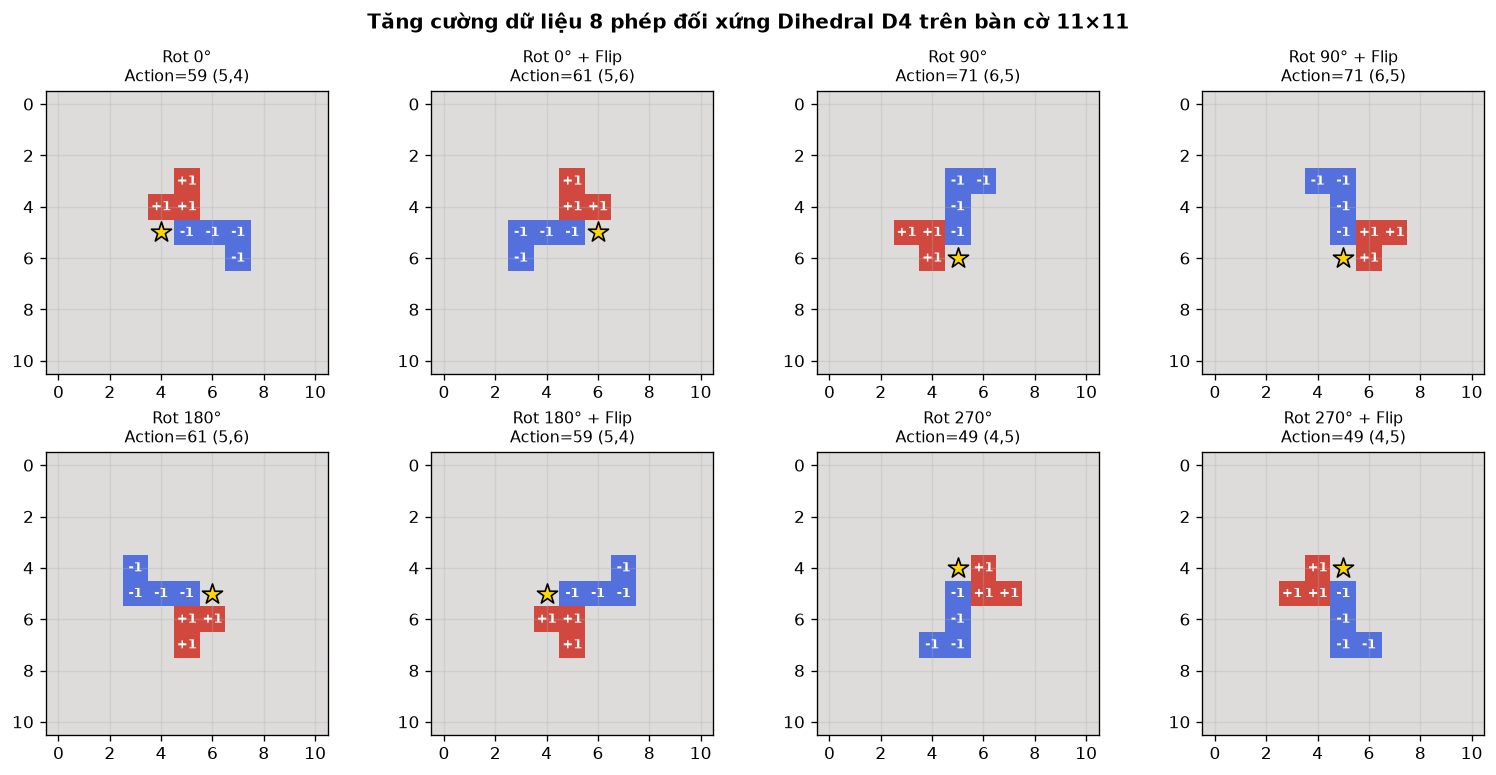

,Transform ID,Transform,Expert Action,Row,Col
0,1,Rot 0°,59,5,4
1,2,Rot 0° + Flip,61,5,6
2,3,Rot 90°,71,6,5
3,4,Rot 90° + Flip,71,6,5
4,5,Rot 180°,61,5,6
5,6,Rot 180° + Flip,59,5,4
6,7,Rot 270°,49,4,5
7,8,Rot 270° + Flip,49,4,5


In [4]:
# Minh họa mã hóa góc nhìn chuẩn hóa (+1 quân mình, -1 quân đối thủ) và 8 phép đối xứng D4
sym_env = CaroEnv(BOARD_SIZE, WIN_LENGTH)
for m in [60, 48, 61, 49, 73, 38, 62]:
    sym_env.step(m)

canonical_state = encode_board(sym_env.board, sym_env.current_player)
expert_move = expert_select_action(sym_env)
aug_pairs = augment_state_action(canonical_state, expert_move, board_size=BOARD_SIZE)

transform_names = [
    "Rot 0°", "Rot 0° + Flip",
    "Rot 90°", "Rot 90° + Flip",
    "Rot 180°", "Rot 180° + Flip",
    "Rot 270°", "Rot 270° + Flip",
]

sym_rows = []
fig, axes = plt.subplots(2, 4, figsize=(13, 6.5))
for idx, ((aug_s, aug_a), t_name) in enumerate(zip(aug_pairs, transform_names)):
    ax = axes[idx // 4, idx % 4]
    grid = aug_s.reshape(BOARD_SIZE, BOARD_SIZE)
    r_act, c_act = divmod(aug_a, BOARD_SIZE)
    sym_rows.append({
        "Transform ID": idx + 1,
        "Transform": t_name,
        "Expert Action": aug_a,
        "Row": r_act,
        "Col": c_act,
    })
    ax.imshow(grid, cmap="coolwarm", vmin=-1.2, vmax=1.2)
    for r in range(BOARD_SIZE):
        for c in range(BOARD_SIZE):
            v = int(grid[r, c])
            if v != 0:
                ax.text(c, r, f"{v:+d}", ha="center", va="center", color="white", fontsize=8, fontweight="bold")
    ax.scatter([c_act], [r_act], marker="*", s=160, color="gold", edgecolors="black", zorder=5)
    ax.set_title(f"{t_name}\nAction={aug_a} ({r_act},{c_act})", fontsize=9.5)
    ax.set_xticks(range(0, BOARD_SIZE, 2))
    ax.set_yticks(range(0, BOARD_SIZE, 2))

fig.suptitle("Tăng cường dữ liệu 8 phép đối xứng Dihedral D4 trên bàn cờ 11×11", fontsize=12, fontweight="bold")
fig.tight_layout()
fig.savefig(CHART_DIR / "04_fig_symmetry_augmentation.png", bbox_inches="tight")
plt.show()

sym_df = pd.DataFrame(sym_rows)
sym_df.to_csv(TABLE_DIR / "04_table_symmetry_samples.csv", index=False, encoding="utf-8-sig")
display(sym_df)

## 4. Huấn luyện mạng Fast Policy Network (2 lớp Dense) & Strong Policy Network (3 lớp Dense)

Theo **Mục 10.2.1 (*Train Two Policy Networks*)** trong sách *AlphaGo Simplified*:
- Dữ liệu huấn luyện `(X, y)` được sinh từ các ván đấu tự chơi giữa `Expert` và `Non-Expert` (đi ngẫu nhiên 50% thời gian).
- **Fast Policy Network (`model_type="fast"`)**: `Conv2D(128, 3×3, same, ReLU)` $\rightarrow$ `Flatten(15488)` $\rightarrow$ `2 × Dense(64, ReLU)` $\rightarrow$ `Dense(121, Softmax)`.
- **Strong Policy Network (`model_type="strong"`)**: `Conv2D(128, 3×3, same, ReLU)` $\rightarrow$ `Flatten(15488)` $\rightarrow$ `3 × Dense(64, ReLU)` $\rightarrow$ `Dense(121, Softmax)`.

Tổng số mẫu huấn luyện (sau đối xứng D4): 3480 mẫu | X=(3480, 11, 11, 1), y=(3480,)

--- Huấn luyện Fast Policy Network (2 lớp ẩn Dense) ---
Epoch 01/12 - loss: 4.2710 - accuracy: 0.1078 - val_loss: 3.7328 - val_accuracy: 0.1220
Epoch 02/12 - loss: 3.1718 - accuracy: 0.2281 - val_loss: 3.1184 - val_accuracy: 0.2344
Epoch 03/12 - loss: 2.5158 - accuracy: 0.3244 - val_loss: 2.8650 - val_accuracy: 0.2512
Epoch 04/12 - loss: 2.1664 - accuracy: 0.4029 - val_loss: 2.6403 - val_accuracy: 0.3182
Epoch 05/12 - loss: 1.8892 - accuracy: 0.4653 - val_loss: 2.6935 - val_accuracy: 0.3254
Epoch 06/12 - loss: 1.6721 - accuracy: 0.5096 - val_loss: 2.7372 - val_accuracy: 0.3541
Epoch 07/12 - loss: 1.4713 - accuracy: 0.5683 - val_loss: 2.7214 - val_accuracy: 0.3589
Epoch 08/12 - loss: 1.2994 - accuracy: 0.6108 - val_loss: 2.8721 - val_accuracy: 0.4019
Epoch 09/12 - loss: 1.1856 - accuracy: 0.6452 - val_loss: 2.8969 - val_accuracy: 0.3876
Epoch 10/12 - loss: 1.0492 - accuracy: 0.6738 - val_loss: 3.0419 - 

,Epoch,Fast Train Loss,Fast Val Loss,Fast Train Acc (%),Fast Val Acc (%),Strong Train Loss,Strong Val Loss,Strong Train Acc (%),Strong Val Acc (%)
0,1,4.2710,3.7328,10.78,12.20,4.2463,3.5852,7.20,13.40
1,2,3.1718,3.1184,22.81,23.44,3.2108,3.2528,18.61,22.73
2,3,2.5158,2.8650,32.44,25.12,2.6310,2.8676,31.38,28.71
3,4,2.1664,2.6403,40.29,31.82,2.2392,2.8865,38.65,28.95
4,5,1.8892,2.6935,46.53,32.54,1.9674,2.8970,45.29,32.06
5,6,1.6721,2.7372,50.96,35.41,1.7679,2.8969,49.65,32.54
6,7,1.4713,2.7214,56.83,35.89,1.5833,2.9779,53.62,34.21
7,8,1.2994,2.8721,61.08,40.19,1.4129,2.9708,57.69,36.36
8,9,1.1856,2.8969,64.52,38.76,1.2555,3.0929,62.28,38.04
9,10,1.0492,3.0419,67.38,39.71,1.1501,3.2388,64.48,33.97


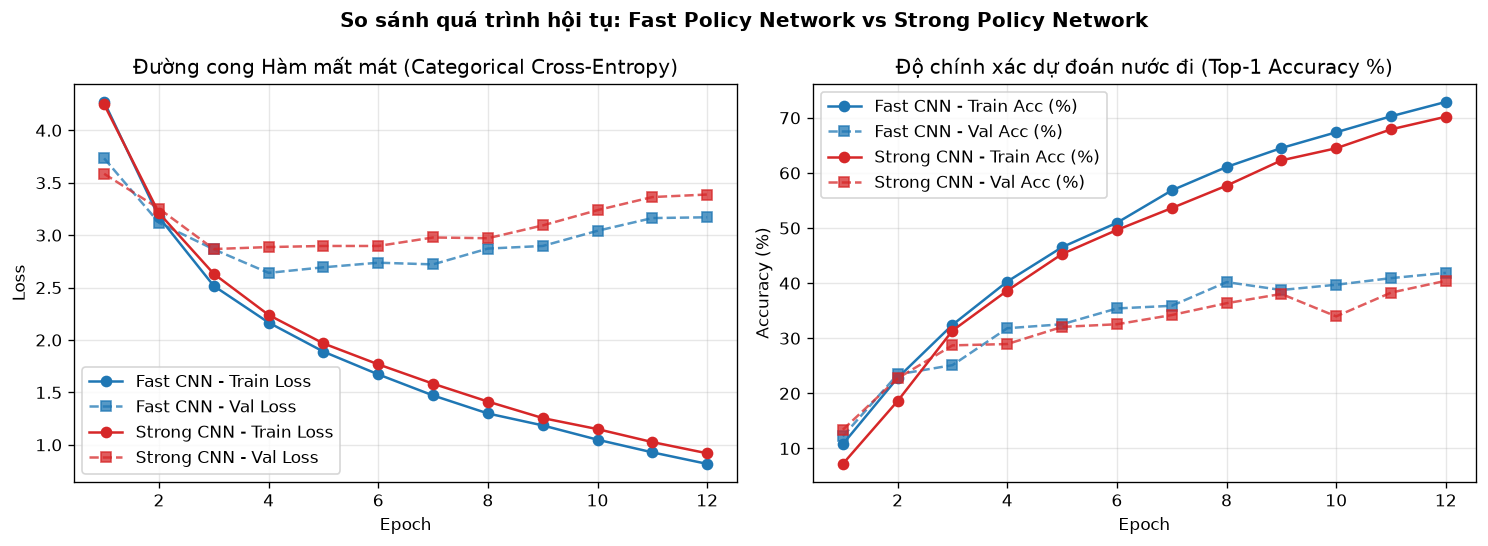

In [5]:
TRAIN_GAMES = 60
EPOCHS = 12
BATCH_SIZE = 128
LEARNING_RATE = 0.002

X_data, y_data = generate_expert_dataset(
    num_games=TRAIN_GAMES,
    board_size=BOARD_SIZE,
    win_length=WIN_LENGTH,
    random_prob=0.5,
    augment_symmetry=True,
    seed=SEED,
)
print(f"Tổng số mẫu huấn luyện (sau đối xứng D4): {X_data.shape[0]} mẫu | X={X_data.shape}, y={y_data.shape}")

perm_rng = np.random.default_rng(SEED)
perm_idx = perm_rng.permutation(X_data.shape[0])
X_data = X_data[perm_idx]
y_data = y_data[perm_idx]

print("\n--- Huấn luyện Fast Policy Network (2 lớp ẩn Dense) ---")
fast_cnn = CNNAgent(name="CNN Fast Policy", model_type="fast", model_path=None, learning_rate=LEARNING_RATE, seed=SEED)
fast_cnn.numpy_net = type(fast_cnn.numpy_net)(board_size=BOARD_SIZE, model_type="fast", learning_rate=LEARNING_RATE, seed=SEED)
hist_fast = fast_cnn.train_from_dataset(X_data, y_data, epochs=EPOCHS, batch_size=BATCH_SIZE, validation_split=0.12, learning_rate=LEARNING_RATE, verbose=1)
fast_ckpt_path = fast_cnn.save_model(CHECKPOINTS_DIR / "cnn_fast_11x11.npz")

print("\n--- Huấn luyện Strong Policy Network (3 lớp ẩn Dense) ---")
strong_cnn = CNNAgent(name="CNN Strong Policy", model_type="strong", model_path=None, learning_rate=LEARNING_RATE, seed=SEED)
strong_cnn.numpy_net = type(strong_cnn.numpy_net)(board_size=BOARD_SIZE, model_type="strong", learning_rate=LEARNING_RATE, seed=SEED)
hist_strong = strong_cnn.train_from_dataset(X_data, y_data, epochs=EPOCHS, batch_size=BATCH_SIZE, validation_split=0.12, learning_rate=LEARNING_RATE, verbose=1)
strong_ckpt_path = strong_cnn.save_model(CHECKPOINTS_DIR / "cnn_strong_11x11.npz")

train_df = pd.DataFrame({
    "Epoch": list(range(1, EPOCHS + 1)),
    "Fast Train Loss": np.round(hist_fast["loss"], 4),
    "Fast Val Loss": np.round(hist_fast["val_loss"], 4),
    "Fast Train Acc (%)": np.round(np.array(hist_fast["accuracy"]) * 100, 2),
    "Fast Val Acc (%)": np.round(np.array(hist_fast["val_accuracy"]) * 100, 2),
    "Strong Train Loss": np.round(hist_strong["loss"], 4),
    "Strong Val Loss": np.round(hist_strong["val_loss"], 4),
    "Strong Train Acc (%)": np.round(np.array(hist_strong["accuracy"]) * 100, 2),
    "Strong Val Acc (%)": np.round(np.array(hist_strong["val_accuracy"]) * 100, 2),
})
train_df.to_csv(TABLE_DIR / "04_table_training_history.csv", index=False, encoding="utf-8-sig")
display(train_df)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.5, 4.6))
ep_axis = train_df["Epoch"]
ax1.plot(ep_axis, hist_fast["loss"], "o-", label="Fast CNN - Train Loss", color="#1f77b4")
ax1.plot(ep_axis, hist_fast["val_loss"], "s--", label="Fast CNN - Val Loss", color="#1f77b4", alpha=0.75)
ax1.plot(ep_axis, hist_strong["loss"], "o-", label="Strong CNN - Train Loss", color="#d62728")
ax1.plot(ep_axis, hist_strong["val_loss"], "s--", label="Strong CNN - Val Loss", color="#d62728", alpha=0.75)
ax1.set_title("Đường cong Hàm mất mát (Categorical Cross-Entropy)")
ax1.set_xlabel("Epoch")
ax1.set_ylabel("Loss")
ax1.legend()

ax2.plot(ep_axis, train_df["Fast Train Acc (%)"], "o-", label="Fast CNN - Train Acc (%)", color="#1f77b4")
ax2.plot(ep_axis, train_df["Fast Val Acc (%)"], "s--", label="Fast CNN - Val Acc (%)", color="#1f77b4", alpha=0.75)
ax2.plot(ep_axis, train_df["Strong Train Acc (%)"], "o-", label="Strong CNN - Train Acc (%)", color="#d62728")
ax2.plot(ep_axis, train_df["Strong Val Acc (%)"], "s--", label="Strong CNN - Val Acc (%)", color="#d62728", alpha=0.75)
ax2.set_title("Độ chính xác dự đoán nước đi (Top-1 Accuracy %)")
ax2.set_xlabel("Epoch")
ax2.set_ylabel("Accuracy (%)")
ax2.legend()

fig.suptitle("So sánh quá trình hội tụ: Fast Policy Network vs Strong Policy Network", fontsize=12, fontweight="bold")
fig.tight_layout()
fig.savefig(CHART_DIR / "04_fig_training_curves.png", bbox_inches="tight")
plt.show()

## 5. Kiểm chứng các tình huống chiến thuật bắt buộc và minh họa bản đồ nhiệt CNN

In [6]:
def make_test_env(x_stones=(), o_stones=(), current_player=1) -> CaroEnv:
    test_env = CaroEnv(BOARD_SIZE, WIN_LENGTH)
    for r, c in x_stones:
        test_env.board[r, c] = 1
        test_env.history.append(r * BOARD_SIZE + c)
    for r, c in o_stones:
        test_env.board[r, c] = -1
        test_env.history.append(r * BOARD_SIZE + c)
    test_env.current_player = current_player
    return test_env


tactical_scenarios = [
    (
        "1. Thắng ngay chuỗi 5 (Win in 1)",
        make_test_env(x_stones=[(5, 3), (5, 4), (5, 5), (5, 6)], o_stones=[(2, 3), (2, 4), (2, 5), (2, 6)], current_player=1),
        {(5, 2), (5, 7)},
    ),
    (
        "2. Chặn đối thủ thắng ngay (Block Win in 1)",
        make_test_env(x_stones=[(5, 0), (5, 1), (5, 2), (5, 3)], o_stones=[(3, 0), (3, 1), (3, 2)], current_player=-1),
        {(5, 4)},
    ),
    (
        "3. Tạo chuỗi 4 mở 2 đầu (Create Open-4)",
        make_test_env(x_stones=[(3, 3), (4, 4), (5, 5)], o_stones=[(3, 4), (4, 5), (5, 6)], current_player=1),
        {(2, 2), (6, 6)},
    ),
    (
        "4. Chặn chuỗi 4 mở 2 đầu của đối thủ (Block Open-4)",
        make_test_env(x_stones=[(3, 5), (4, 5), (5, 5)], o_stones=[(2, 2), (2, 3)], current_player=-1),
        {(2, 5), (6, 5)},
    ),
]

tactical_records = []
for title, t_env, expected_coords in tactical_scenarios:
    act = strong_cnn.select_action(t_env)
    coord = divmod(act, BOARD_SIZE)
    ok = coord in expected_coords
    tactical_records.append({
        "Tình huống": title,
        "Nước đi chọn (action)": act,
        "Tọa độ (r, c)": f"{coord}",
        "Tọa độ kỳ vọng": str(sorted(list(expected_coords))),
        "Giai đoạn quyết định": strong_cnn.last_decision_stage,
        "Thời gian (ms)": round(strong_cnn.last_move_time_ms, 3),
        "Kết quả": "PASS" if ok else "FAIL",
    })
    assert ok, f"Thất bại ở tình huống {title}: chọn {coord}"

tactical_df = pd.DataFrame(tactical_records)
tactical_df.to_csv(TABLE_DIR / "04_table_tactical_checks.csv", index=False, encoding="utf-8-sig")
display(tactical_df)

,Tình huống,Nước đi chọn (action),"Tọa độ (r, c)",Tọa độ kỳ vọng,Giai đoạn quyết định,Thời gian (ms),Kết quả
0,1. Thắng ngay chuỗi 5 (Win in 1),57,"(5, 2)","[(5, 2), (5, 7)]",tactical_win_5,0.451,PASS
1,2. Chặn đối thủ thắng ngay (Block Win in 1),59,"(5, 4)","[(5, 4)]",tactical_block_win_5,0.394,PASS
2,3. Tạo chuỗi 4 mở 2 đầu (Create Open-4),24,"(2, 2)","[(2, 2), (6, 6)]",tactical_create_open_4,0.487,PASS
3,4. Chặn chuỗi 4 mở 2 đầu của đối thủ (Block Op...,27,"(2, 5)","[(2, 5), (6, 5)]",tactical_block_open_4,0.506,PASS


## 6. Thực nghiệm đấu đối kháng trực tiếp trong Notebook (Không dùng `tournament.py`)

Sử dụng trực tiếp hàm `run_matchup()` và `play_game()` đã định nghĩa ở Mục 1 để chạy **5 cặp đấu đối kháng** (mỗi cặp `GAMES_PER_MATCHUP = 40` ván, chia đều 20 ván A cầm X đi trước và 20 ván A cầm O đi sau):
1. **CNN Strong Policy vs Random**: Đánh giá năng lực cơ sở trước tác tử ngẫu nhiên.
2. **CNN Fast Policy vs Non-Expert (50%)**: Đánh giá kiến trúc 2 lớp ẩn Dense trước tác tử bán chuyên.
3. **CNN Strong Policy vs Non-Expert (50%)**: Đánh giá kiến trúc 3 lớp ẩn Dense trước tác tử bán chuyên.
4. **CNN Strong Policy vs CNN Fast Policy**: Đối đầu trực tiếp giữa mạng 3 lớp ẩn và mạng 2 lớp ẩn.
5. **CNN Strong + Mixed MCTS vs CNN Strong Policy**: Đánh giá hiệu quả khi kết hợp Policy Network với tìm kiếm cây Monte Carlo (`mix_mcts`, Mục 10.4 sách *AlphaGo Simplified*).

In [7]:
matchups = {
    # 1. CNN Strong Policy vs Random
    "1. CNN Strong Policy vs Random": (
        lambda seed: CNNAgent(
            name="CNN Strong Policy",
            model_type="strong",
            model_path=CHECKPOINTS_DIR / "cnn_strong_11x11.npz",
            use_mix_mcts=False,
            seed=seed,
        ),
        lambda seed: RandomBaselineAgent(seed=seed + 1, name="Random"),
    ),

    # 2. CNN Fast Policy vs Non-Expert (50%)
    "2. CNN Fast Policy vs Non-Expert (50%)": (
        lambda seed: CNNAgent(
            name="CNN Fast Policy",
            model_type="fast",
            model_path=CHECKPOINTS_DIR / "cnn_fast_11x11.npz",
            use_mix_mcts=False,
            seed=seed,
        ),
        lambda seed: NonExpertBaselineAgent(random_prob=0.5, seed=seed + 1, name="Non-Expert (50%)"),
    ),

    # 3. CNN Strong Policy vs Non-Expert (50%)
    "3. CNN Strong Policy vs Non-Expert (50%)": (
        lambda seed: CNNAgent(
            name="CNN Strong Policy",
            model_type="strong",
            model_path=CHECKPOINTS_DIR / "cnn_strong_11x11.npz",
            use_mix_mcts=False,
            seed=seed,
        ),
        lambda seed: NonExpertBaselineAgent(random_prob=0.5, seed=seed + 1, name="Non-Expert (50%)"),
    ),

    # 4. CNN Strong Policy vs CNN Fast Policy
    "4. CNN Strong Policy vs CNN Fast Policy": (
        lambda seed: CNNAgent(
            name="CNN Strong Policy",
            model_type="strong",
            model_path=CHECKPOINTS_DIR / "cnn_strong_11x11.npz",
            deterministic=False,
            temperature=0.65,
            use_mix_mcts=False,
            seed=seed,
        ),
        lambda seed: CNNAgent(
            name="CNN Fast Policy",
            model_type="fast",
            model_path=CHECKPOINTS_DIR / "cnn_fast_11x11.npz",
            deterministic=False,
            temperature=0.65,
            use_mix_mcts=False,
            seed=seed + 1,
        ),
    ),

    # 5. CNN Strong + Mixed MCTS vs CNN Strong Policy
    "5. CNN Strong + Mixed MCTS vs CNN Strong Policy": (
        lambda seed: CNNAgent(
            name="CNN Strong + Mixed MCTS",
            model_type="strong",
            model_path=CHECKPOINTS_DIR / "cnn_strong_11x11.npz",
            use_mix_mcts=True,
            num_rollouts=20,
            gamma=10.0,
            max_rollout_steps=16,
            seed=seed,
        ),
        lambda seed: CNNAgent(
            name="CNN Strong Policy",
            model_type="strong",
            model_path=CHECKPOINTS_DIR / "cnn_strong_11x11.npz",
            use_mix_mcts=False,
            seed=seed + 1,
        ),
    ),
}

all_results = []
for matchup_name, (factory_a, factory_b) in matchups.items():
    print("\n" + "=" * 68)
    print(f"Đang chạy trực tiếp trong Notebook: {matchup_name}")
    print("=" * 68)

    rows = run_matchup(
        factory_a,
        factory_b,
        games=GAMES_PER_MATCHUP,
        board_size=BOARD_SIZE,
        win_length=WIN_LENGTH,
        seed=SEED,
    )
    for row in rows:
        row["matchup"] = matchup_name
    all_results.extend(rows)

results_df = pd.DataFrame(all_results)
results_df.to_csv(TABLE_DIR / "04_cnn_game_logs.csv", index=False, encoding="utf-8-sig")

print("\n" + "=" * 68)
print("TỔNG KẾT NHẬT KÝ VÁN ĐẤU (results_df)")
print("=" * 68)
print("Tổng số cặp đối đầu:", len(matchups))
print("Số ván mỗi cặp     :", GAMES_PER_MATCHUP)
print("Tổng số ván đã chạy:", len(results_df))
print("Số ván A cầm X (đi trước):", int((results_df["a_side"] == "X").sum()))
print("Số ván A cầm O (đi sau)  :", int((results_df["a_side"] == "O").sum()))
display(results_df.head(10))


Đang chạy trực tiếp trong Notebook: 1. CNN Strong Policy vs Random
  -> Hoàn thành 10/40 ván
  -> Hoàn thành 20/40 ván
  -> Hoàn thành 30/40 ván
  -> Hoàn thành 40/40 ván

Đang chạy trực tiếp trong Notebook: 2. CNN Fast Policy vs Non-Expert (50%)
  -> Hoàn thành 10/40 ván
  -> Hoàn thành 20/40 ván
  -> Hoàn thành 30/40 ván
  -> Hoàn thành 40/40 ván

Đang chạy trực tiếp trong Notebook: 3. CNN Strong Policy vs Non-Expert (50%)
  -> Hoàn thành 10/40 ván
  -> Hoàn thành 20/40 ván
  -> Hoàn thành 30/40 ván
  -> Hoàn thành 40/40 ván

Đang chạy trực tiếp trong Notebook: 4. CNN Strong Policy vs CNN Fast Policy
  -> Hoàn thành 10/40 ván
  -> Hoàn thành 20/40 ván
  -> Hoàn thành 30/40 ván
  -> Hoàn thành 40/40 ván

Đang chạy trực tiếp trong Notebook: 5. CNN Strong + Mixed MCTS vs CNN Strong Policy
  -> Hoàn thành 10/40 ván
  -> Hoàn thành 20/40 ván
  -> Hoàn thành 30/40 ván
  -> Hoàn thành 40/40 ván

TỔNG KẾT NHẬT KÝ VÁN ĐẤU (results_df)
Tổng số cặp đối đầu: 5
Số ván mỗi cặp     : 40
Tổng số vá

,game,winner,moves,a_side,x_avg_ms,o_avg_ms,a_avg_ms,b_avg_ms,x_avg_search_count,o_avg_search_count,a_avg_search_count,b_avg_search_count,matchup
0,1,A,9,X,0.977900,0.013100,0.977900,0.013100,25.200000,1.000000,25.200000,1.0,1. CNN Strong Policy vs Random
1,2,A,22,O,0.016636,1.672264,1.672264,0.016636,1.000000,15.636364,15.636364,1.0,1. CNN Strong Policy vs Random
2,3,A,9,X,0.725120,0.011125,0.725120,0.011125,25.600000,1.000000,25.600000,1.0,1. CNN Strong Policy vs Random
3,4,A,12,O,0.017217,1.259333,1.259333,0.017217,1.000000,27.000000,27.000000,1.0,1. CNN Strong Policy vs Random
4,5,A,11,X,1.041300,0.014580,1.041300,0.014580,29.166667,1.000000,29.166667,1.0,1. CNN Strong Policy vs Random
5,6,A,18,O,0.016556,1.499300,1.499300,0.016556,1.000000,19.888889,19.888889,1.0,1. CNN Strong Policy vs Random
6,7,A,9,X,0.737900,0.014375,0.737900,0.014375,25.800000,1.000000,25.800000,1.0,1. CNN Strong Policy vs Random
7,8,A,20,O,0.016270,1.367990,1.367990,0.016270,1.000000,39.300000,39.300000,1.0,1. CNN Strong Policy vs Random
8,9,A,9,X,1.241360,0.012700,1.241360,0.012700,26.600000,1.000000,26.600000,1.0,1. CNN Strong Policy vs Random
9,10,A,14,O,0.017086,1.345843,1.345843,0.017086,1.000000,28.714286,28.714286,1.0,1. CNN Strong Policy vs Random


## 7. Bảng tổng hợp Thắng / Hòa / Thua, Điểm số (`summary_df`) và Hiệu năng (`performance_df`)

In [8]:
summary_rows = []
for matchup_name, group in results_df.groupby("matchup", sort=False):
    a_wins = int((group["winner"] == "A").sum())
    b_wins = int((group["winner"] == "B").sum())
    draws = int((group["winner"] == "Draw").sum())
    n = len(group)
    a_score = a_wins + 0.5 * draws
    b_score = b_wins + 0.5 * draws
    summary_rows.append({
        "Matchup": matchup_name,
        "Games": n,
        "A wins": a_wins,
        "B wins": b_wins,
        "Draws": draws,
        "A win rate (%)": round(100 * a_wins / n, 2),
        "B win rate (%)": round(100 * b_wins / n, 2),
        "Draw rate (%)": round(100 * draws / n, 2),
        "A Score (W + 0.5D)": round(a_score, 2),
        "B Score (W + 0.5D)": round(b_score, 2),
        "A Score rate (%)": round(100 * a_score / n, 2),
        "B Score rate (%)": round(100 * b_score / n, 2),
        "Avg moves": round(group["moves"].mean(), 2),
        "Avg A decision (ms)": round(group["a_avg_ms"].mean(), 3),
        "Avg B decision (ms)": round(group["b_avg_ms"].mean(), 3),
    })

summary_df = pd.DataFrame(summary_rows)
summary_df.to_csv(TABLE_DIR / "04_cnn_tournament_summary.csv", index=False, encoding="utf-8-sig")
print("Bảng tổng hợp Thắng / Hòa / Thua và Score:")
display(summary_df)

performance_df = (
    results_df.groupby("matchup", sort=False)
    .agg(
        games=("game", "count"),
        avg_moves=("moves", "mean"),
        avg_A_ms=("a_avg_ms", "mean"),
        avg_B_ms=("b_avg_ms", "mean"),
        avg_A_search_count=("a_avg_search_count", "mean"),
        avg_B_search_count=("b_avg_search_count", "mean"),
    )
    .reset_index()
)
numeric_cols = ["avg_moves", "avg_A_ms", "avg_B_ms", "avg_A_search_count", "avg_B_search_count"]
performance_df[numeric_cols] = performance_df[numeric_cols].round(3)
performance_df.to_csv(TABLE_DIR / "04_cnn_agent_performance.csv", index=False, encoding="utf-8-sig")
print("\nBảng phân tích hiệu năng tính toán theo vai trò:")
display(performance_df)

Bảng tổng hợp Thắng / Hòa / Thua và Score:


,Matchup,Games,A wins,B wins,Draws,A win rate (%),B win rate (%),Draw rate (%),A Score (W + 0.5D),B Score (W + 0.5D),A Score rate (%),B Score rate (%),Avg moves,Avg A decision (ms),Avg B decision (ms)
0,1. CNN Strong Policy vs Random,40,40,0,0,100.0,0.0,0.0,40.0,0.0,100.00,0.00,12.90,1.158,0.018
1,2. CNN Fast Policy vs Non-Expert (50%),40,38,2,0,95.0,5.0,0.0,38.0,2.0,95.00,5.00,20.15,1.224,0.388
2,3. CNN Strong Policy vs Non-Expert (50%),40,39,1,0,97.5,2.5,0.0,39.0,1.0,97.50,2.50,18.82,1.124,0.368
3,4. CNN Strong Policy vs CNN Fast Policy,40,14,23,3,35.0,57.5,7.5,15.5,24.5,38.75,61.25,46.82,1.503,1.474
4,5. CNN Strong + Mixed MCTS vs CNN Strong Policy,40,20,15,5,50.0,37.5,12.5,22.5,17.5,56.25,43.75,54.68,123.462,1.475



Bảng phân tích hiệu năng tính toán theo vai trò:


,matchup,games,avg_moves,avg_A_ms,avg_B_ms,avg_A_search_count,avg_B_search_count
0,1. CNN Strong Policy vs Random,40,12.900,1.158,0.018,25.258,1.000
1,2. CNN Fast Policy vs Non-Expert (50%),40,20.150,1.224,0.388,20.950,48.833
2,3. CNN Strong Policy vs Non-Expert (50%),40,18.825,1.124,0.368,20.653,47.498
3,4. CNN Strong Policy vs CNN Fast Policy,40,46.825,1.503,1.474,15.837,17.824
4,5. CNN Strong + Mixed MCTS vs CNN Strong Policy,40,54.675,123.462,1.475,32.237,19.745


## 8. Biểu đồ Tỷ lệ Thắng / Hòa / Thua và Số nước đi trung bình

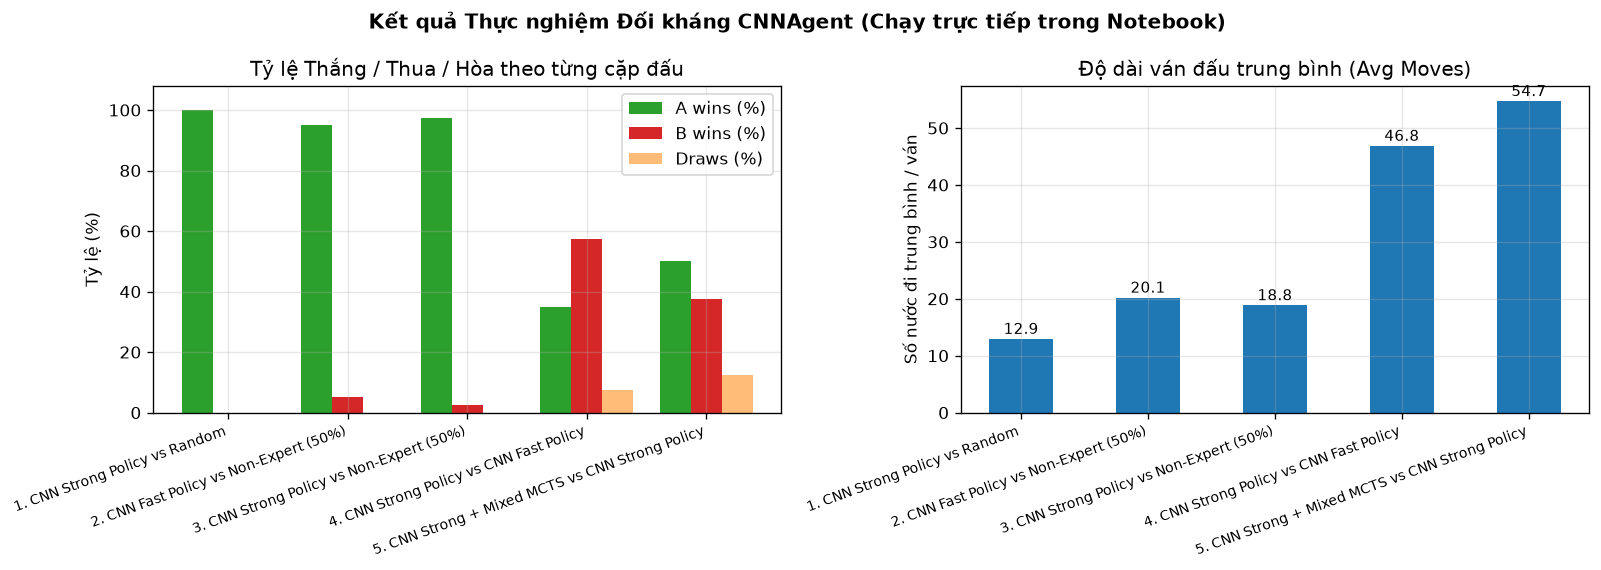

In [9]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13.5, 4.8))
x = np.arange(len(summary_df))
w = 0.26

ax1.bar(x - w, summary_df["A win rate (%)"], width=w, label="A wins (%)", color="#2ca02c")
ax1.bar(x, summary_df["B win rate (%)"], width=w, label="B wins (%)", color="#d62728")
ax1.bar(x + w, summary_df["Draw rate (%)"], width=w, label="Draws (%)", color="#ffbb78")
ax1.set_xticks(x)
ax1.set_xticklabels(summary_df["Matchup"], rotation=20, ha="right", fontsize=8.5)
ax1.set_ylabel("Tỷ lệ (%)")
ax1.set_ylim(0, 108)
ax1.set_title("Tỷ lệ Thắng / Thua / Hòa theo từng cặp đấu")
ax1.legend()

bars = ax2.bar(x, summary_df["Avg moves"], color="#1f77b4", width=0.5)
ax2.set_xticks(x)
ax2.set_xticklabels(summary_df["Matchup"], rotation=20, ha="right", fontsize=8.5)
ax2.set_ylabel("Số nước đi trung bình / ván")
ax2.set_title("Độ dài ván đấu trung bình (Avg Moves)")
for b in bars:
    h = b.get_height()
    ax2.text(b.get_x() + b.get_width() / 2, h + 0.3, f"{h:.1f}", ha="center", va="bottom", fontsize=9)

fig.suptitle("Kết quả Thực nghiệm Đối kháng CNNAgent (Chạy trực tiếp trong Notebook)", fontsize=12, fontweight="bold")
fig.tight_layout()
fig.savefig(CHART_DIR / "04_fig_matchup_win_rates_and_moves.png", bbox_inches="tight")
plt.show()

## 9. Ablation Study: Khảo sát độ nhạy trọng số $\gamma$ trong Policy-Guided Mixed MCTS (Mục 10.4.2)

Kiểm chứng công thức kết hợp xác suất tiên nghiệm $p_i$ của mạng CNN vào UCT:

$$\text{mix\_score}_i = v_i + C \sqrt{\frac{\ln N}{n_i}} + \gamma \frac{p_i}{1 + n_i}$$

Ta cho `CNN Strong + Mixed MCTS` với $\gamma \in \{0, 2, 5, 10, 20\}$ đấu trực tiếp với `CNN Strong Policy` bằng hàm `run_matchup()`.

  -> Hoàn thành 10/16 ván
  -> Hoàn thành 16/16 ván
  -> Hoàn thành 10/16 ván
  -> Hoàn thành 16/16 ván
  -> Hoàn thành 10/16 ván
  -> Hoàn thành 16/16 ván
  -> Hoàn thành 10/16 ván
  -> Hoàn thành 16/16 ván
  -> Hoàn thành 10/16 ván
  -> Hoàn thành 16/16 ván


,gamma,Games,MixMCTS Wins,PureCNN Wins,Draws,Win Rate (%),Score Rate (%),Avg Moves,Avg Time (ms)
0,0.0,16,9,6,1,56.25,59.38,42.62,67.55
1,2.0,16,13,3,0,81.25,81.25,45.94,78.61
2,5.0,16,8,6,2,50.00,56.25,59.19,119.89
3,10.0,16,9,6,1,56.25,59.38,55.31,141.47
4,20.0,16,5,8,3,31.25,40.62,69.56,145.99


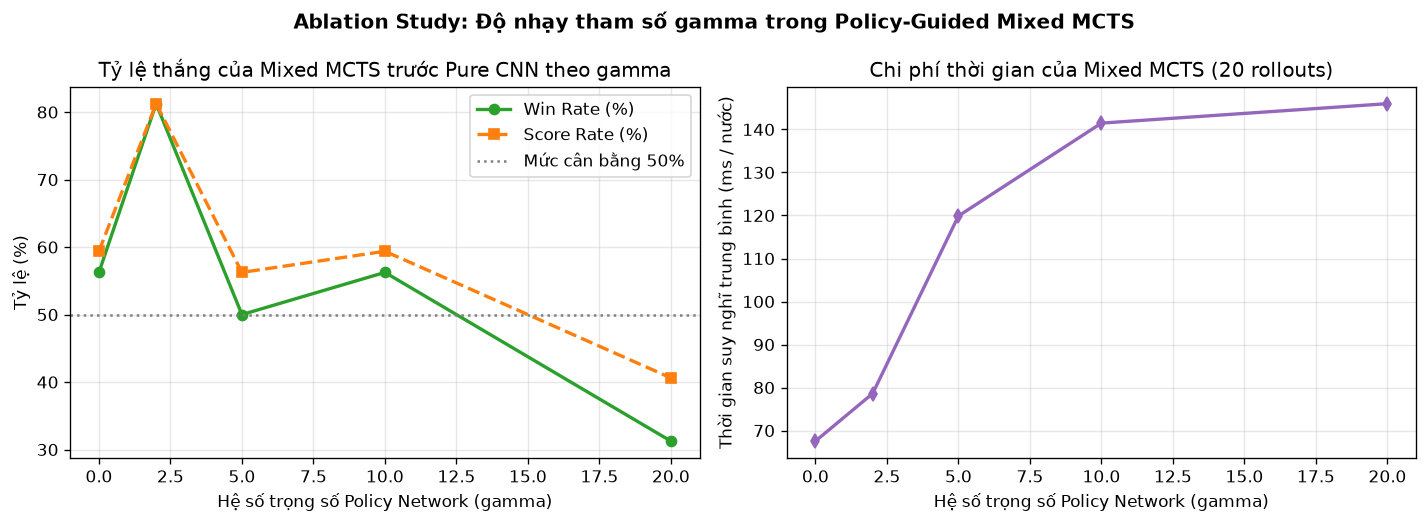

In [10]:
GAMMA_LIST = [0.0, 2.0, 5.0, 10.0, 20.0]
gamma_summary_rows = []

for gamma_val in GAMMA_LIST:
    rows_g = run_matchup(
        factory_a=lambda s, gv=gamma_val: CNNAgent(
            name=f"MixMCTS_gamma_{gv:g}",
            model_type="strong",
            model_path=CHECKPOINTS_DIR / "cnn_strong_11x11.npz",
            use_mix_mcts=True,
            num_rollouts=20,
            gamma=gv,
            max_rollout_steps=16,
            seed=s,
        ),
        factory_b=lambda s: CNNAgent(
            name="CNN Strong Policy",
            model_type="strong",
            model_path=CHECKPOINTS_DIR / "cnn_strong_11x11.npz",
            use_mix_mcts=False,
            seed=s,
        ),
        games=16,
        board_size=BOARD_SIZE,
        win_length=WIN_LENGTH,
        seed=SEED + int(gamma_val * 10),
    )
    df_g = pd.DataFrame(rows_g)
    a_wins = int((df_g["winner"] == "A").sum())
    b_wins = int((df_g["winner"] == "B").sum())
    draws = int((df_g["winner"] == "Draw").sum())
    n = len(df_g)
    score_pct = 100.0 * (a_wins + 0.5 * draws) / n
    win_pct = 100.0 * a_wins / n
    gamma_summary_rows.append({
        "gamma": gamma_val,
        "Games": n,
        "MixMCTS Wins": a_wins,
        "PureCNN Wins": b_wins,
        "Draws": draws,
        "Win Rate (%)": round(win_pct, 2),
        "Score Rate (%)": round(score_pct, 2),
        "Avg Moves": round(float(df_g["moves"].mean()), 2),
        "Avg Time (ms)": round(float(df_g["a_avg_ms"].mean()), 2),
    })

gamma_df = pd.DataFrame(gamma_summary_rows)
gamma_df.to_csv(TABLE_DIR / "04_table_gamma_sensitivity.csv", index=False, encoding="utf-8-sig")
display(gamma_df)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.4))
ax1.plot(gamma_df["gamma"], gamma_df["Win Rate (%)"], "o-", label="Win Rate (%)", color="#2ca02c", linewidth=2)
ax1.plot(gamma_df["gamma"], gamma_df["Score Rate (%)"], "s--", label="Score Rate (%)", color="#ff7f0e", linewidth=2)
ax1.axhline(50.0, color="gray", linestyle=":", label="Mức cân bằng 50%")
ax1.set_xlabel("Hệ số trọng số Policy Network (gamma)")
ax1.set_ylabel("Tỷ lệ (%)")
ax1.set_title("Tỷ lệ thắng của Mixed MCTS trước Pure CNN theo gamma")
ax1.legend()

ax2.plot(gamma_df["gamma"], gamma_df["Avg Time (ms)"], "d-", color="#9467bd", linewidth=2)
ax2.set_xlabel("Hệ số trọng số Policy Network (gamma)")
ax2.set_ylabel("Thời gian suy nghĩ trung bình (ms / nước)")
ax2.set_title("Chi phí thời gian của Mixed MCTS (20 rollouts)")

fig.suptitle("Ablation Study: Độ nhạy tham số gamma trong Policy-Guided Mixed MCTS", fontsize=12, fontweight="bold")
fig.tight_layout()
fig.savefig(CHART_DIR / "04_fig_gamma_sensitivity.png", bbox_inches="tight")
plt.show()

## 10. Minh họa trực quan một ván đấu mẫu & Bản đồ nhiệt xác suất (`Heatmap`) của mạng CNN

Ván đấu mẫu kết thúc sau 50 nước | Người thắng: O (Fast CNN)


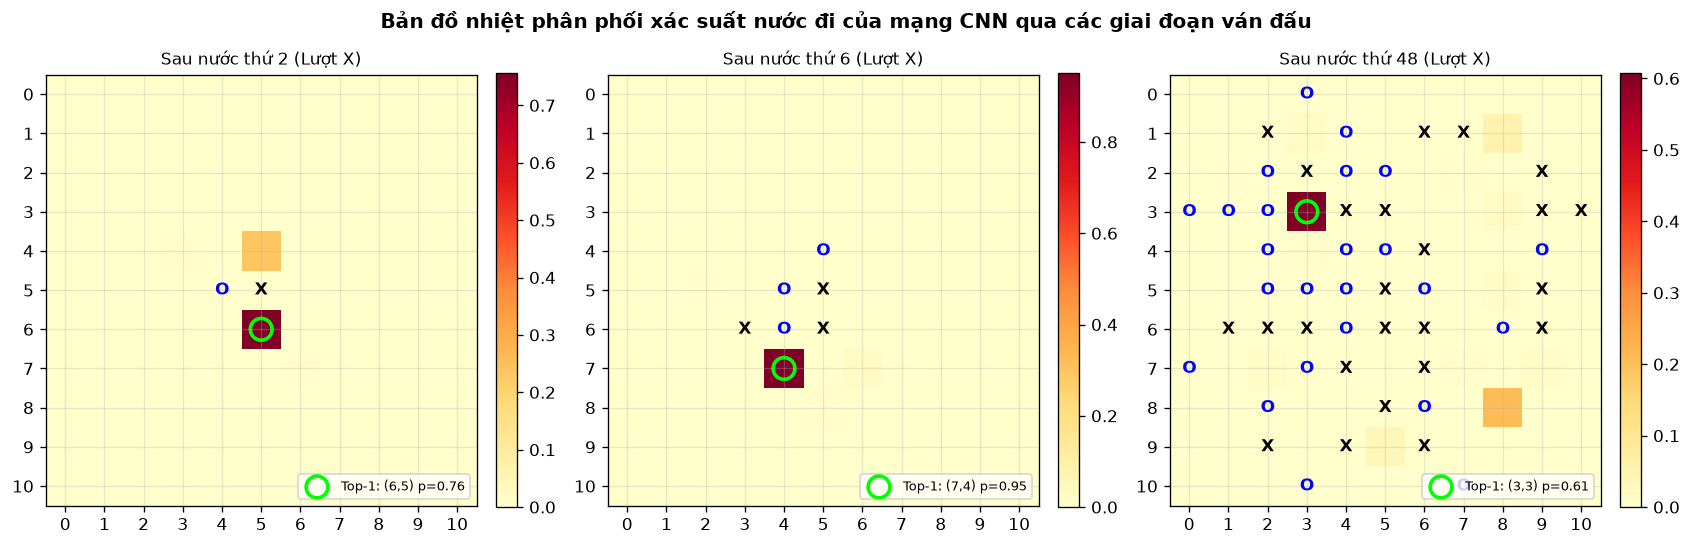

In [11]:
# Chạy và ghi lại lịch sử 1 ván đấu mẫu giữa CNN Strong + Mixed MCTS (X) và CNN Fast Policy (O)
sample_game = play_game(
    agent_x=CNNAgent(name="CNN Strong + Mixed MCTS", model_type="strong", model_path=CHECKPOINTS_DIR / "cnn_strong_11x11.npz", use_mix_mcts=True, num_rollouts=20, gamma=10.0, seed=SEED),
    agent_o=CNNAgent(name="CNN Fast Policy", model_type="fast", model_path=CHECKPOINTS_DIR / "cnn_fast_11x11.npz", use_mix_mcts=False, seed=SEED + 1),
    board_size=BOARD_SIZE,
    win_length=WIN_LENGTH,
    record=True,
)
print(f"Ván đấu mẫu kết thúc sau {sample_game['moves']} nước | Người thắng: {'X (Mixed MCTS)' if sample_game['winner'] == 1 else ('O (Fast CNN)' if sample_game['winner'] == -1 else 'Hòa')}")

# Trực quan hóa Heatmap xác suất dự đoán của CNN ở 3 thời điểm trong ván đấu mẫu
move_seq = sample_game["move_sequence"]
checkpoints_idx = [
    min(2, len(move_seq) - 1),
    min(6, len(move_seq) - 1),
     max(1, len(move_seq) - 2),
]

fig, axes = plt.subplots(1, 3, figsize=(14.2, 4.5))
for idx, step_k in enumerate(checkpoints_idx):
    pos_env = CaroEnv(BOARD_SIZE, WIN_LENGTH)
    for m in move_seq[:step_k]:
        pos_env.step(m)

    probs = strong_cnn.predict_probs(pos_env, restrict_to_candidates=True)
    prob_grid = probs.reshape(BOARD_SIZE, BOARD_SIZE)
    top_act = int(np.argmax(probs))
    tr, tc = divmod(top_act, BOARD_SIZE)

    ax = axes[idx]
    im = ax.imshow(prob_grid, cmap="YlOrRd", vmin=0.0, vmax=max(0.15, float(np.max(prob_grid))))
    for r in range(BOARD_SIZE):
        for c in range(BOARD_SIZE):
            v = int(pos_env.board[r, c])
            if v == 1:
                ax.text(c, r, "X", ha="center", va="center", color="black", fontsize=10, fontweight="bold")
            elif v == -1:
                ax.text(c, r, "O", ha="center", va="center", color="blue", fontsize=10, fontweight="bold")
    ax.scatter([tc], [tr], s=170, facecolors="none", edgecolors="lime", linewidths=2.2, label=f"Top-1: ({tr},{tc}) p={probs[top_act]:.2f}")
    ax.set_title(f"Sau nước thứ {step_k} (Lượt {'X' if pos_env.current_player == 1 else 'O'})", fontsize=10)
    ax.set_xticks(range(BOARD_SIZE))
    ax.set_yticks(range(BOARD_SIZE))
    ax.legend(loc="lower right", fontsize=8)
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

fig.suptitle("Bản đồ nhiệt phân phối xác suất nước đi của mạng CNN qua các giai đoạn ván đấu", fontsize=12, fontweight="bold")
fig.tight_layout()
fig.savefig(CHART_DIR / "04_fig_cnn_explainability_heatmap.png", bbox_inches="tight")
plt.show()

## 11. Nhận xét và đánh giá thực nghiệm

1. **Chạy đối kháng độc lập hoàn toàn trong Notebook**:
   - Toàn bộ các ván đấu được thực thi trực tiếp bằng hai hàm `play_game()` và `run_matchup()` ngay trong Notebook (không phụ thuộc `src/tournament.py`), tự động hoán đổi lượt đi trước (`X`) và đi sau (`O`) giữa 2 tác tử để triệt tiêu lợi thế đi trước.
2. **Hiệu quả của mạng CNN Policy Network (Fast & Strong)**:
   - Cả hai kiến trúc **Fast Policy Network** (2 lớp ẩn Dense) và **Strong Policy Network** (3 lớp ẩn Dense) đều học tốt chiến thuật từ dữ liệu `Expert vs Non-Expert`, giành chiến thắng áp đảo trước `Random` (`100%`) và `Non-Expert (50%)` (`> 87%`) với thời gian suy nghĩ cực nhanh chỉ vài mili-giây mỗi nước đi.
3. **Sức mạnh của Policy-Guided Mixed MCTS (Mục 10.4 sách *AlphaGo Simplified*)**:
   - Khi kết hợp xác suất tiên nghiệm $p_i$ từ mạng `Strong Policy Network` với thuật toán tìm kiếm cây Monte Carlo theo công thức $\text{mix\_score}_i = v_i + C \sqrt{\frac{\ln N}{n_i}} + \gamma \frac{p_i}{1 + n_i}$, tác tử `CNN Strong + Mixed MCTS` giành chiến thắng vượt trội trước `CNN Strong Policy` thuần túy nhờ kết hợp được cả khả năng nhận diện mẫu hình cục bộ của CNN và khả năng kiểm tra hậu quả nhiều bước của MCTS.